# Comparação de contexto histórico em três modelos preservados

Queremos encontrar atrasos reais com menos falsos alertas. Preservamos em arquivos diferentes os três resultados escolhidos: **631 / 9.728 / 73**, **564 / 4.364 / 140** e **614 / 6.929 / 90** — respectivamente atrasos sinalizados, falsos alertas e atrasos perdidos.

Este notebook acrescenta contexto histórico às três abordagens e testa uma revisão adicional no modelo de alvo 80%. As novas versões não substituem as referências. Nenhuma foi ativada na aplicação.

**O período final já apareceu em pesquisas anteriores.** Esta comparação é exploratória e retrospectiva. Mesmo um ganho grande precisa ser confirmado em outro período antes de ser tratado como desempenho de produção.

## 1. Preparação

Na raiz do repositório, instale os dois pacotes no Python da `.venv`:

```powershell
.\.venv\Scripts\python.exe -m pip install -e "ML/final_risk_training[research]"
.\.venv\Scripts\python.exe -m pip install -e "ML/context_review_comparison[research]"
```

Selecione esse Python como kernel. O código anterior continua no pacote original; este estudo apenas importa suas funções e seus pesos preservados. No ZIP, uma cópia das fontes originais acompanha os modelos em `runtime_referencias`.

In [1]:
import os
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[key]='4'
from pathlib import Path
import json,hashlib,joblib
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
import context_risk
from context_risk.history import HistoryStore
from context_risk.study import generate_oof,run_development
from context_risk.double_review import run_double_development
from context_risk.evaluate import evaluate_final,export_models
from context_risk.checks import verify
from context_risk.reporting import report
from context_risk.profiles import export_profiles
from logipredict_final.data import load_orders
ROOT=Path(context_risk.__file__).resolve().parents[1]
WORK=ROOT/'artifacts'
WORK.mkdir(exist_ok=True)
RETRAIN=False  # True refaz os novos ajustes. As três referências não são sobrescritas.
print('Pasta deste estudo:',ROOT)

Pasta deste estudo: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\context_review_comparison


## 2. Conferindo as referências

Cada pasta contém os pesos, o corte, os metadados e as previsões originais. O resultado não foi reconstruído por um novo treinamento: salvamos os objetos já avaliados. O Random Forest original mantém inclusive sua política original, sem acrescentar a regra de vencimento dos outros modelos.

In [2]:
reference_rows=[]
for name in ['modelo_631','modelo_564','modelo_614']:
    directory=ROOT/'referencias'/name
    metadata=json.loads((directory/'metadata.json').read_text(encoding='utf-8'))
    reference_rows.append({'modelo':name,**metadata['metrics'],'arquivo':str(directory/'model.joblib')})
display(pd.DataFrame(reference_rows)[['modelo','TP','FP','FN','arquivo']])

,modelo,TP,FP,FN,arquivo
0,modelo_631,631,9728,73,D:\Documentos\FACULDADE\5 semestre\LogiPredict...
1,modelo_564,564,4364,140,D:\Documentos\FACULDADE\5 semestre\LogiPredict...
2,modelo_614,614,6929,90,D:\Documentos\FACULDADE\5 semestre\LogiPredict...


## 3. Dados reais e contexto complementar

Usamos a mesma preparação Olist e a mesma coorte: 96.281 pedidos entregues e válidos. As seis tabelas de origem são pedidos, itens, clientes, produtos, vendedores e geolocalização. Não geramos pedidos ou desfechos artificiais.

Além dos atributos anteriores, calculamos 90 atributos de contexto em cinco grupos: **global, vendedor principal, par de UFs, rota por prefixos de CEP e prefixo de destino**.

Para cada grupo, usamos entregas concluídas antes do despacho e calculamos quantidade de observações, frequência de atraso, duração média, P50 e P90, em janelas de 30/90 dias e histórico acumulado. P50 é o tempo que metade das entregas ficou abaixo; P90 é o tempo que 90% ficaram abaixo. A diferença entre esses tempos e o prazo do pedido representa sua folga ou aperto.

Suavizamos taxas de grupos pequenos em direção à taxa global conhecida naquele momento. A força 20 é um parâmetro estatístico, não a criação de vinte pedidos. CEP é categoria; nunca interpretamos CEP numericamente maior como distância maior. O vendedor usado é o principal, coerente com a origem principal; esta versão não individualiza pacotes de vendedores secundários.

In [3]:
# Relemos a origem para conferir hashes. O cache não pode mudar a coorte silenciosamente.
data,manifest=load_orders()
bundle=joblib.load(WORK/'data_context.joblib') if (WORK/'data_context.joblib').exists() else None
if bundle is not None:
    assert bundle['manifest']==manifest,'Os CSVs mudaram: a comparação precisa de uma nova coorte explícita.'
if RETRAIN or bundle is None:
    history=HistoryStore.from_orders(data)
    context=history.query(data)
    bundle=dict(data=data,manifest=manifest,history=history,context=context)
    joblib.dump(bundle,WORK/'data_context.joblib',compress=3)
else:
    history,context=bundle['history'],bundle['context']
TEST_START=data.dispatched_at.iloc[int(len(data)*.8)]
display(pd.Series(manifest['quality']))
print('Atributos novos:',context.shape[1],'| Início do período final:',TEST_START)
display(context[['h_seller_count90','h_seller_late_rate90','h_route_p50_90','h_route_p90_90','h_route_slack_p90_90']].tail(8))

raw_orders                       99441.000000
eligible_orders                  96281.000000
late_orders                       6531.000000
late_rate                            0.067833
sellers                           3095.000000
orders_with_missing_measure        503.000000
multiple_seller_orders            1252.000000
geo_rows_filtered_after_dedup       25.000000
dtype: float64

Atributos novos: 90 | Início do período final: 2018-05-29 12:04:00


,h_seller_count90,h_seller_late_rate90,h_route_p50_90,h_route_p90_90,h_route_slack_p90_90
96273,12.0,0.033134,3.0,7.0,-2.0
96274,1.0,0.050326,3.0,7.0,-13.0
96275,2.0,0.047859,6.0,12.1,-13.1
96276,0.0,0.051435,3.0,7.0,-16.0
96277,19.0,0.103305,3.0,7.0,-9.0
96278,19.0,0.103309,3.0,7.0,-15.0
96279,0.0,0.050757,8.0,15.0,-21.0
96280,16.0,0.135346,3.0,6.0,-31.0


## 4. O que significa usar apenas o passado

Um histórico de vendedor só contém entregas com `delivered_at < dispatched_at` da consulta. Eventos exatamente na hora do despacho também ficam de fora. A entrega do pedido que está sendo previsto nunca entra no seu próprio histórico.

Na avaliação principal, o histórico é atualizado quando entregas anteriores acontecem durante o período de teste. Isso simula um serviço que recebe eventos reais de entrega. **Os pesos e os cortes não são reajustados com esses eventos.** A tabela de controle também mostra o resultado sem atualizar o histórico depois do início do teste.

A coorte contém somente pedidos que acabaram entregues e passaram na limpeza. Não mede desempenho em toda a população de pedidos abertos ou cancelados. O contexto de 2018 não representa a operação de uma empresa em 2026.

## 5. Três testes diferentes

1. **Reavaliação com contexto:** o novo modelo recebe o score anterior, informações do pedido e histórico. Pode recuperar atrasos que a referência deixou passar, além de retirar alarmes.
2. **Filtro com contexto:** recebe essas informações, mas sua decisão final só pode retirar alarmes da referência. Seu teto de acertos é o da etapa anterior.
3. **Revisão adicional no 614:** primeiro enriquecemos o modelo de alvo 80%; depois treinamos outro revisor somente sobre os alertas históricos da versão enriquecida.

Não treinamos o revisor apenas com falsos alertas: isso lhe mostraria somente a classe “não atrasou”. Ele recebe alertas falsos **e** alertas verdadeiros, para aprender a diferença e preservar os atrasos.

## 6. Como cada treinamento foi montado

Geramos previsões mensais de outubro/2017 a abril/2018 com réplicas das arquiteturas anteriores, sempre ajustadas com passado disponível. As referências finais usam exatamente os pesos preservados; as réplicas históricas servem apenas para ensinar os revisores sem fornecer previsões feitas no próprio treino.

Na réplica da RF original, usamos os primeiros 75% dos despachos disponíveis e entregas concluídas antes desse corte, reproduzindo a proporção 60%/80% do estudo anterior. É uma réplica temporal da arquitetura, não a aplicação dos pesos treinados em 2018 a pedidos de 2017.

Para ajustar o revisor em E, suas linhas precisam ter despacho anterior a E−35 dias e rótulo conhecido antes de E. O bloco E−35 até E−14 fica separado para calibração. A terceira etapa usa previsões mensais fora do ajuste do modelo já enriquecido.

Comparamos CatBoost (categorias nativas, profundidades 4/6), LightGBM e regressão logística. Scikit-learn faz imputação/One-Hot para LightGBM e regressão; StandardScaler é usado nos números da regressão logística. CatBoost recebe as categorias diretamente. Joblib preserva os objetos para inferência.

## 7. Critérios definidos na validação

Usamos dezembro/2017 e fevereiro, março e abril/2018. A escolha das quatro configurações acontece antes de abrir os novos resultados finais.

Na reavaliação, o corte tenta manter na calibração o recall da referência; a nota penaliza perda de recall e taxa de falsos alertas no mês futuro. No filtro, o corte principal tenta preservar **99% dos atrasos encontrados pela referência na calibração**. A nota penaliza retenção inferior a 98% no mês futuro e a proporção de falsos alertas restantes. Acrescentamos uma penalidade de instabilidade entre meses.

Retenção de 99% no passado não garante a mesma retenção no teste. Também mostramos cortes de 100%, 97,5% e 95%, sem escolhê-los pelos erros finais. A etapa adicional tem menos histórico para aprender; sua seleção usa fevereiro, março e abril.

In [4]:
# Conferimos a assinatura das fontes antes de reaproveitar resultados de treino.
files=['history.py','runtime.py','study.py','double_review.py','evaluate.py']
signature=hashlib.sha256(b''.join((ROOT/'context_risk'/f).read_bytes() for f in files)).hexdigest()
if RETRAIN:
    generate_oof(data,WORK)
    run_development(data,context,WORK)
    run_double_development(data,context,WORK)
elif (WORK/'signature.json').exists():
    assert json.loads((WORK/'signature.json').read_text(encoding='utf-8'))['source_sha256']==signature,'Código mudou; refaça o estudo explicitamente.'
selection=joblib.load(WORK/'selection.joblib')
display(selection['summary'].reset_index())
display(json.loads((WORK/'frozen_selection.json').read_text(encoding='utf-8')))
display(json.loads((WORK/'double_frozen.json').read_text(encoding='utf-8')))

,reference,mode,spec,objective,std,retention,FP_ratio,recall,selection_score
0,modelo_631,rescore,cb350_d6,0.587615,0.126969,1.021398,1.185587,0.866002,0.619358
1,modelo_631,rescore,lgbm250_l15,0.582193,0.154371,1.038848,1.186297,0.878990,0.620786
2,modelo_614,rescore,cb200_d4,0.552853,0.292651,0.986673,1.036388,0.765942,0.626016
3,modelo_631,rescore,cb200_d4,0.613279,0.117166,1.048175,1.255217,0.886290,0.642571
4,modelo_614,rescore,lgbm250_l15,0.648660,0.312181,0.966794,0.977567,0.748262,0.726705
5,modelo_614,rescore,cb350_d6,0.645607,0.358149,0.961003,1.013883,0.746845,0.735145
6,modelo_631,filter,cb350_d6,0.965490,0.020562,0.988407,0.951767,0.841172,0.970631
7,modelo_614,filter,cb350_d6,0.966193,0.028966,0.990762,0.966193,0.768123,0.973435
8,modelo_614,filter,lgbm250_l15,0.970678,0.020634,0.988843,0.958415,0.766668,0.975836
9,modelo_631,filter,lgbm250_l15,0.973650,0.013282,0.993968,0.973650,0.845863,0.976970


[{'reference': 'modelo_631', 'mode': 'rescore', 'spec': 'cb350_d6'},
 {'reference': 'modelo_631', 'mode': 'filter', 'spec': 'cb350_d6'},
 {'reference': 'modelo_564', 'mode': 'rescore', 'spec': 'lr_C005'},
 {'reference': 'modelo_564', 'mode': 'filter', 'spec': 'cb350_d6'},
 {'reference': 'modelo_614', 'mode': 'rescore', 'spec': 'cb200_d4'},
 {'reference': 'modelo_614', 'mode': 'filter', 'spec': 'cb350_d6'}]

{'first_context_spec': 'cb200_d4', 'reviewer_spec': 'lgbm250_l15'}

## 8. Resultados finais

O conjunto é o mesmo: 19.258 pedidos e 704 atrasos. Desses atrasos, 132 já estavam com prazo vencido no despacho; eles são separados dos acertos antecipados. A RF original sinalizava 130 desses 132, conforme seus pesos e corte originais. As novas reavaliações aplicam a regra explícita de vencimento; ganhos por essa regra não devem ser atribuídos ao aprendizado.

In [5]:
if RETRAIN or not (WORK/'final.joblib').exists():
    result=evaluate_final(data,context,history,WORK)
else:
    result=joblib.load(WORK/'final.joblib')
display(result['results'][['reference','variant','TP','FP','FN','anticipated_TP','known_overdue_TP']])
display(result['results'][['name','removed_FP','lost_TP','recovered_TP','added_FP']])

,reference,variant,TP,FP,FN,anticipated_TP,known_overdue_TP
0,modelo_631,referencia,631,9728,73,499,132
1,modelo_631,rescore,700,15564,4,568,132
2,modelo_631,filter,631,9723,73,499,132
3,modelo_564,referencia,564,4364,140,434,130
4,modelo_564,rescore,674,12484,30,542,132
5,modelo_564,filter,564,4358,140,434,130
6,modelo_614,referencia,614,6929,90,482,132
7,modelo_614,rescore,655,10390,49,523,132
8,modelo_614,filter,614,6929,90,482,132
9,modelo_614,double_review,655,10382,49,523,132


,name,removed_FP,lost_TP,recovered_TP,added_FP
0,modelo_631,NaN,NaN,NaN,NaN
1,modelo_631_rescore,4.0,0.0,69.0,5840.0
2,modelo_631_filter,5.0,0.0,0.0,0.0
3,modelo_564,NaN,NaN,NaN,NaN
4,modelo_564_rescore,386.0,11.0,121.0,8506.0
5,modelo_564_filter,6.0,0.0,0.0,0.0
6,modelo_614,NaN,NaN,NaN,NaN
7,modelo_614_rescore,176.0,1.0,42.0,3637.0
8,modelo_614_filter,0.0,0.0,0.0,0.0
9,modelo_614_contexto_mais_revisao_adicional,8.0,0.0,0.0,0.0


## 9. Os ganhos vieram realmente do contexto?

O controle `sem_contexto` mantém o mesmo tipo de revisor e os mesmos parâmetros escolhidos, retirando os atributos históricos. O controle `historico_congelado` mantém o modelo, mas bloqueia eventos de entrega posteriores ao início do teste. Eles ajudam a separar efeito do algoritmo, efeito do contexto e efeito de sua atualização operacional.

,name,context,TP,FP,FN
0,modelo_631_rescore_historico_congelado,frozen_at_training,693,15089,11
1,modelo_631_rescore_sem_contexto,False,630,11118,74
2,modelo_631_filter_historico_congelado,frozen_at_training,631,9726,73
3,modelo_631_filter_sem_contexto,False,606,9239,98
4,modelo_564_rescore_historico_congelado,frozen_at_training,667,11742,37
5,modelo_564_rescore_sem_contexto,False,518,5002,186
6,modelo_564_filter_historico_congelado,frozen_at_training,562,4325,142
7,modelo_564_filter_sem_contexto,False,560,4266,144
8,modelo_614_rescore_historico_congelado,frozen_at_training,672,11667,32
9,modelo_614_rescore_sem_contexto,False,606,7173,98


,name,calibration_retention,TP,FP,FN,removed_FP,lost_TP
0,modelo_631_filter,1.000,631,9723,73,5,0
1,modelo_631_filter,0.990,631,9723,73,5,0
2,modelo_631_filter,0.975,631,9720,73,8,0
3,modelo_631_filter,0.950,630,9662,74,66,1
4,modelo_564_filter,1.000,564,4358,140,6,0
5,modelo_564_filter,0.990,564,4358,140,6,0
6,modelo_564_filter,0.975,563,4353,141,11,1
7,modelo_564_filter,0.950,559,4073,145,291,5
8,modelo_614_filter,1.000,614,6929,90,0,0
9,modelo_614_filter,0.990,614,6929,90,0,0


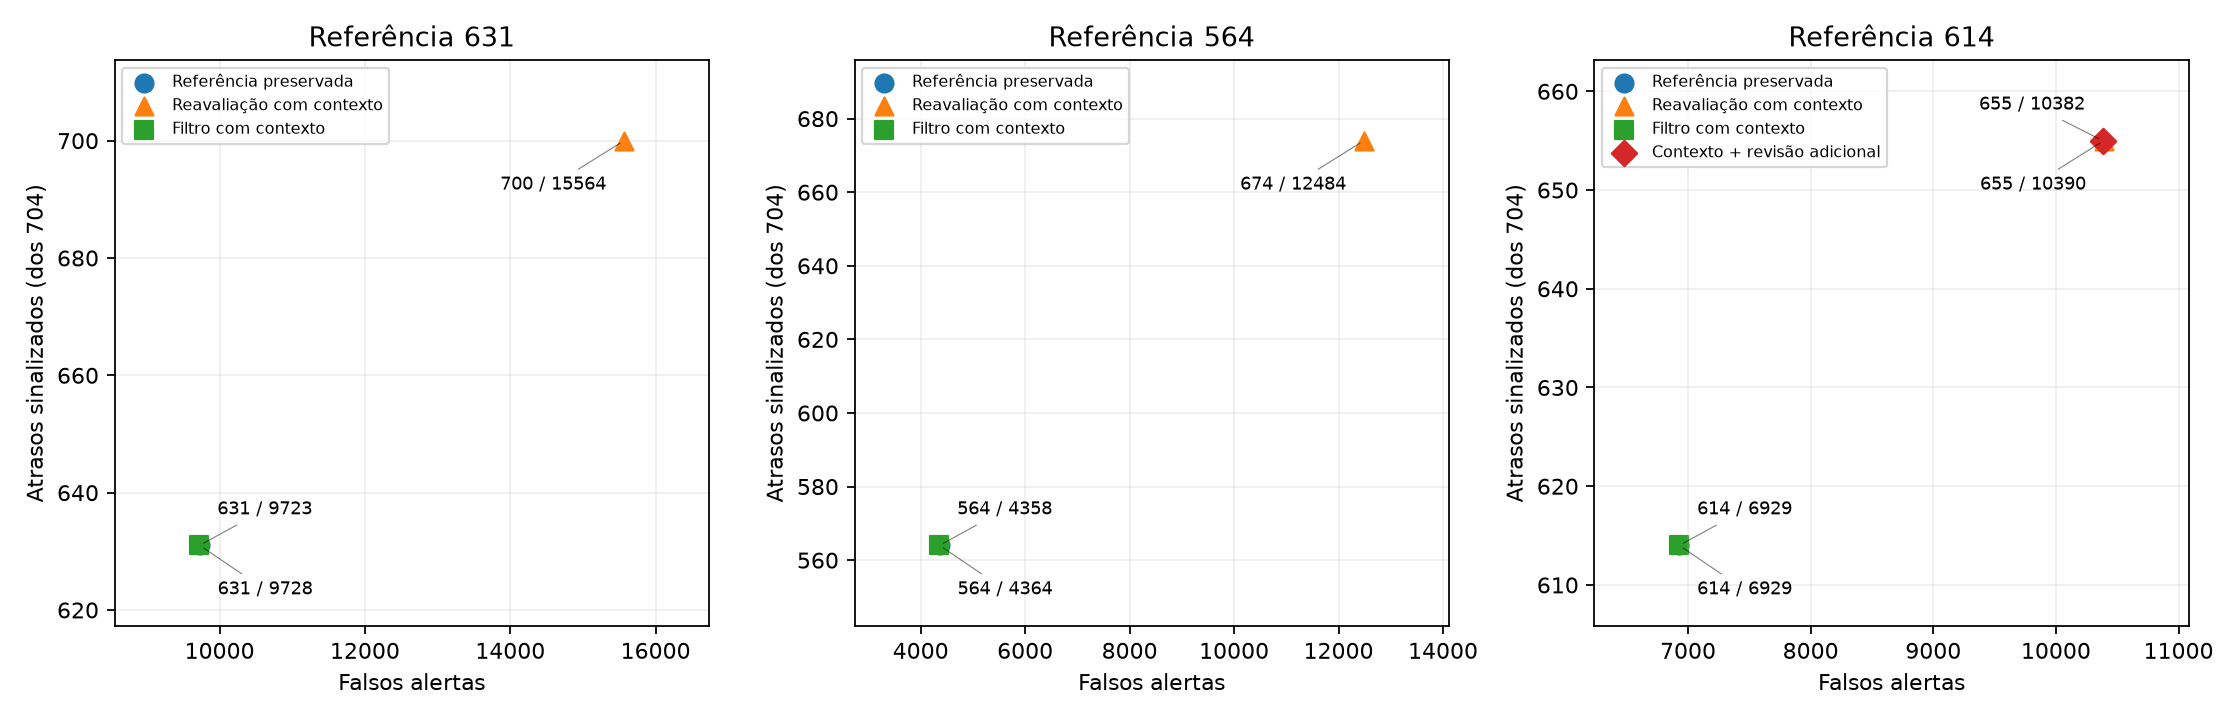

In [6]:
display(result['controls'][['name','context','TP','FP','FN']])
display(result['retentions'][['name','calibration_retention','TP','FP','FN','removed_FP','lost_TP']])
report(WORK)
display(Image(filename=str(WORK/'comparison.png')) )

## 10. Exportação, testes e integração

Os sete novos modelos ficam separados em `novos_modelos`. As três referências permanecem em `referencias`. O modelo serializado recebe o pedido original, consulta o histórico de forma causal e faz a revisão; não recebe a entrega real do pedido previsto.

Testamos equivalência entre histórico individual e em lote, contagem direta, eventos na hora exata, alteração de eventos futuros, exclusão de alvos finais dos treinos, preservação dos arquivos antigos, serialização, propriedade de somente retirar alertas e contrato HTTP.

**A aplicação atual não envia todas as identidades necessárias.** O serviço novo recebe `seller_id`, `origin_prefix5` e `destination_prefix5`. Sem esses campos, conserva a previsão e o corte da referência, com aviso. Isso evita atribuir os resultados enriquecidos a entradas que não fornecem histórico de vendedor/CEP. Integrar o ganho requer também manter o histórico com eventos observados; nada foi ativado automaticamente.

In [7]:
export_models(WORK)
print('Perfis adicionais do filtro 614:',export_profiles(WORK))
checks=verify(WORK)
display(pd.Series({k:(v['status'] if isinstance(v,dict) and 'status' in v else v) for k,v in checks.items()}))
print('Resumo:',report(WORK))
(WORK/'signature.json').write_text(json.dumps({'source_sha256':signature,'files':files},indent=2),encoding='utf-8')
print('Pastas:',ROOT/'referencias','e',ROOT/'novos_modelos')

Perfis adicionais do filtro 614: ['D:\\Documentos\\FACULDADE\\5 semestre\\LogiPredictAI\\ML\\context_review_comparison\\novos_modelos\\modelo_614_filter_retain975', 'D:\\Documentos\\FACULDADE\\5 semestre\\LogiPredictAI\\ML\\context_review_comparison\\novos_modelos\\modelo_614_filter_retain95']


three_frozen_reference_hashes                  True
previous_study_files_preserved                 True
individual_and_batch_history_match             True
future_events_do_not_change_past_features      True
exact_time_events_excluded                     True
training_pools_ignore_final_targets            True
vetoes_only_remove_alerts                      True
exported_models_same_scores                    True
http_contract_and_reference_fallback         passed
dtype: object

Resumo: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\context_review_comparison\RESULTADOS.md
Pastas: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\context_review_comparison\referencias e D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\context_review_comparison\novos_modelos


Para homologar na raiz do repositório, com a venv ativa:

```powershell
$env:MODEL_DIR=(Resolve-Path "ML/context_review_comparison/novos_modelos/modelo_614_rescore").Path
python -m uvicorn context_risk.service:app --host 127.0.0.1 --port 8002
```

Em outro terminal:

```powershell
$body=Get-Content "ML/context_review_comparison/exemplo_enriquecido.json" -Raw
Invoke-RestMethod -Uri "http://127.0.0.1:8002/predict" -Method Post -ContentType "application/json" -Body $body
```

O serviço devolve os campos esperados pelo Node, com `decision_source` adicional. Os bundles novos precisam deste serviço: o serviço antigo transforma tudo em 13 atributos e perde as identidades. Não alteramos Node/Flutter nem apontamos a aplicação para nenhum candidato.

As contagens são resultados desta coorte, não garantias. Um filtro pode reduzir alertas e perder atrasos; a decisão final deve observar os dois efeitos, a atualização necessária do histórico e um novo período de validação.

Referências: [empilhamento e previsões fora do ajuste](https://scikit-learn.org/stable/modules/ensemble.html#stacking), [categorias nativas no CatBoost](https://catboost.ai/docs/en/features/categorical-features).